In [42]:
import pandas as pd
from pathlib import Path

# Đường dẫn dataset
data_path = Path("../data/raw/shopee_reviews_dataset.jsonl")

# Đọc file JSONL
df = pd.read_json(data_path, lines=True)

print("Kích thước dataset:", df.shape)
print("Các cột:", df.columns.tolist())

display(df.head())

Kích thước dataset: (9599, 4)
Các cột: ['id', 'review', 'rating', 'label']


,id,review,rating,label
0,74263765409,Hương vị:thom Chắc do bên giao hàng bị vỡ mấy gói,3,negative
1,11104151002,Hương thơm:nhẹ nhàng Lợi ích:phục hồi cấp ẩm Mẹo:không có Shop đóng gói cẩn thận chu đáo lắm Ship nhanh Shiper thân thiện Sẽ ủng hộ tiếp tục nha Tks,5,positive
2,15888299382,"Chất lượng sản phẩm:ok Đúng với mô tả:đúng Lần đầu mua ở shop. Đóng gói kĩ, sản phẩm chất lượng, dễ dán. Nên mua nha. Mình sẽ quay lại ủng hộ.",5,positive
3,81030214453,Độ tuổi sử dụng:em bes Chất lượng sản phẩm:tot Sản phẩm đúng mô tả sẽ mua lại hình ảnh mang tc nhận xu,5,positive
4,88484377297,"Hương vị:Mix vị, Tím Mình mua 64 gói (32 gói mix vị + 32 gói tím). Tuy nhiên shop giao thiếu tận 4 gói. Đây là lần thứ hai shop giao hàng thiếu cho mình. Có phản ánh vs shop nhưng ko thấy cải thiện. Trong kinh doanh, uy tín là quan trọng. Shop hứa cải thiện nhưng ko làm được. Mình rất thất vọng và sẽ ko bao giờ quay lại ủng hộ nữa.",1,negative


In [43]:
# 1. Kích thước dữ liệu
print("Dataset shape:", df.shape)

# 2. Kiểu dữ liệu
print("\nData types:")
print(df.dtypes)

# 3. Giá trị thiếu
print("\nMissing values:")
print(df.isnull().sum())

# 4. Review rỗng hoặc chỉ chứa khoảng trắng
print("\nEmpty reviews:")
print(df["review"].fillna("").str.strip().eq("").sum())

# 5. Review trùng lặp
print("\nDuplicate reviews:")
print(df["review"].duplicated().sum())

# 6. Phân bố nhãn
print("\nLabel distribution:")
print(df["label"].value_counts())

# 7. Phân bố rating
print("\nRating distribution:")
print(df["rating"].value_counts().sort_index())

Dataset shape: (9599, 4)

Data types:
id        int64
review      str
rating    int64
label       str
dtype: object

Missing values:
id        0
review    0
rating    0
label     0
dtype: int64

Empty reviews:
0

Duplicate reviews:
0

Label distribution:
label
negative    5965
positive    3634
Name: count, dtype: int64

Rating distribution:
rating
1    2972
2    1230
3    1782
4      96
5    3519
Name: count, dtype: int64


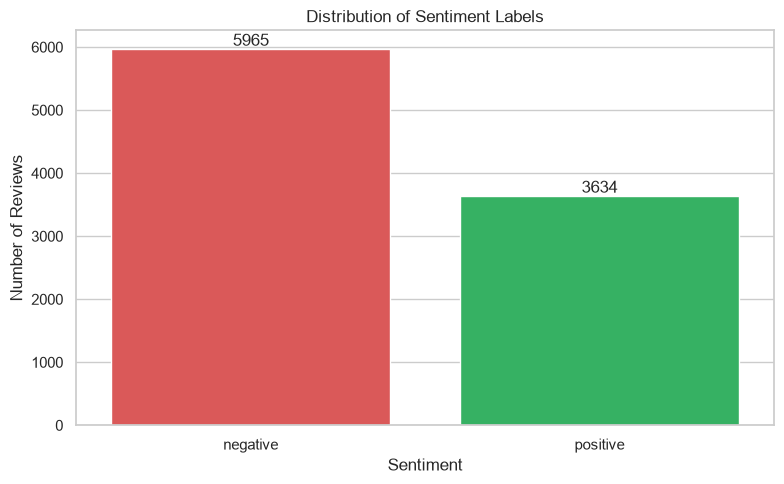

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="label",
    order=["negative", "positive"],
    hue="label",
    palette={
        "negative": "#EF4444",
        "positive": "#22C55E"
    },
    legend=False
)

for container in ax.containers:
    ax.bar_label(container)

plt.title("Distribution of Sentiment Labels")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

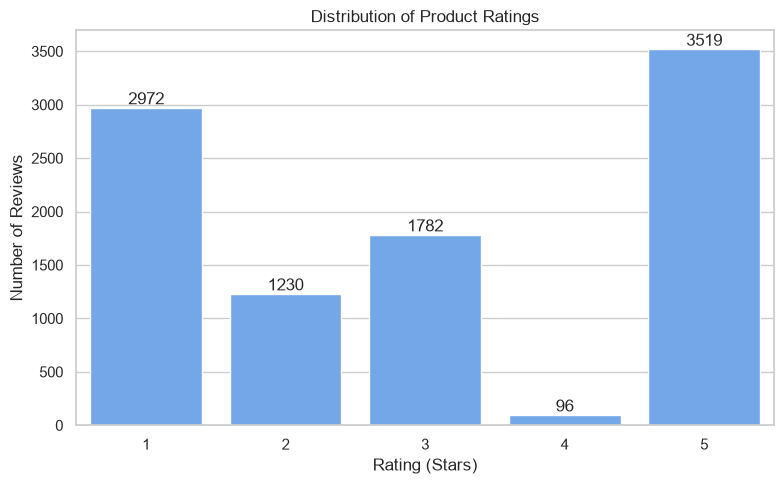

In [45]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="rating",
    order=[1, 2, 3, 4, 5],
    color="#60A5FA"
)

for container in ax.containers:
    ax.bar_label(container)

plt.title("Distribution of Product Ratings")
plt.xlabel("Rating (Stars)")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

label,negative,positive
rating,,
1,2958,14
2,1221,9
3,1691,91
4,29,67
5,66,3453


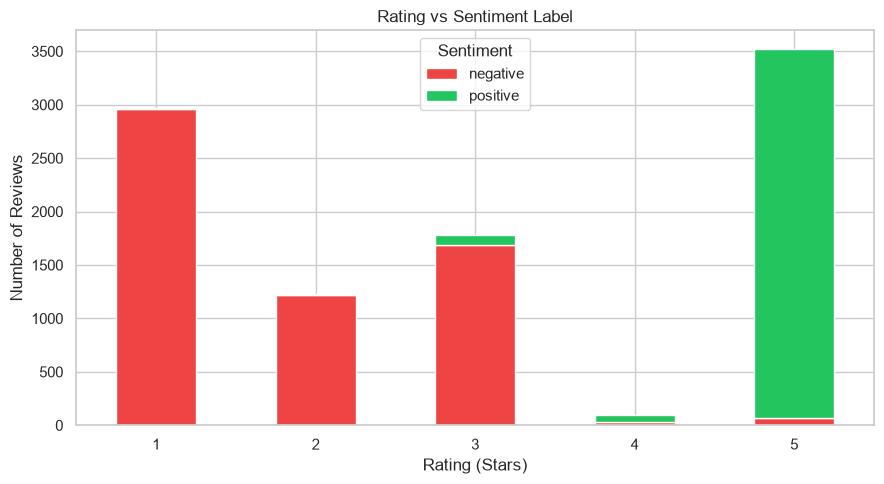

In [46]:
import pandas as pd

rating_label_table = pd.crosstab(
    df["rating"],
    df["label"]
)

display(rating_label_table)

rating_label_table.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5),
    color=["#EF4444", "#22C55E"]
)

plt.title("Rating vs Sentiment Label")
plt.xlabel("Rating (Stars)")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.legend(title="Sentiment")
plt.tight_layout()
plt.show()

In [47]:
# Tạo các đặc trưng độ dài phục vụ EDA
df["char_count"] = df["review"].str.len()
df["word_count"] = df["review"].str.split().str.len()

print("Thống kê độ dài review:")
display(df[["char_count", "word_count"]].describe())

print("\nĐộ dài theo nhãn cảm xúc:")
display(
    df.groupby("label")[["char_count", "word_count"]]
      .agg(["mean", "median", "min", "max"])
)

Thống kê độ dài review:


,char_count,word_count
count,9599.000000,9599.000000
mean,133.919575,30.215335
std,109.318574,24.969633
min,20.000000,3.000000
25%,71.000000,16.000000
50%,106.000000,24.000000
75%,159.000000,36.000000
max,2021.000000,444.000000



Độ dài theo nhãn cảm xúc:


char_count                  word_count                
                mean median min   max       mean median min  max
label                                                           
negative  144.563286  109.0  20  2021  33.254317   25.0   4  444
positive  116.448542  104.0  20  1108  25.227023   22.0   3  241

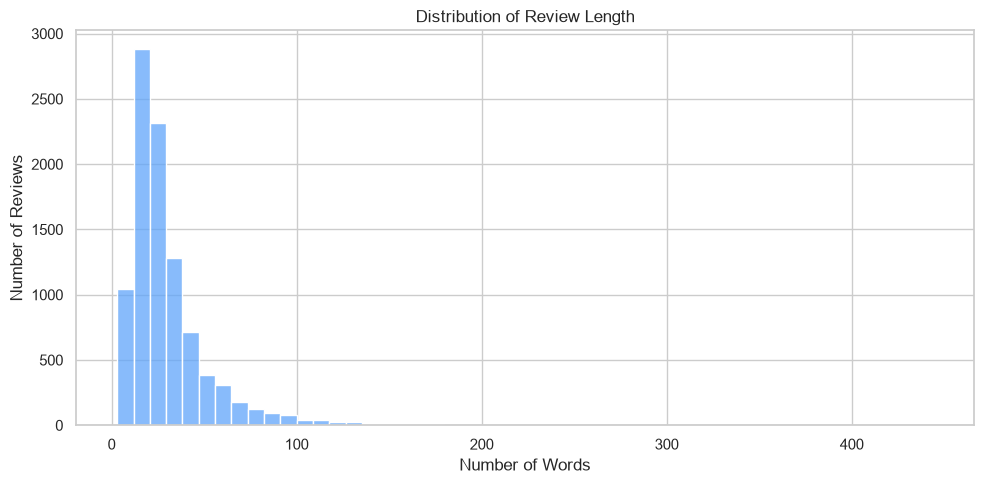

In [48]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="word_count",
    bins=50,
    color="#60A5FA"
)

plt.title("Distribution of Review Length")
plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

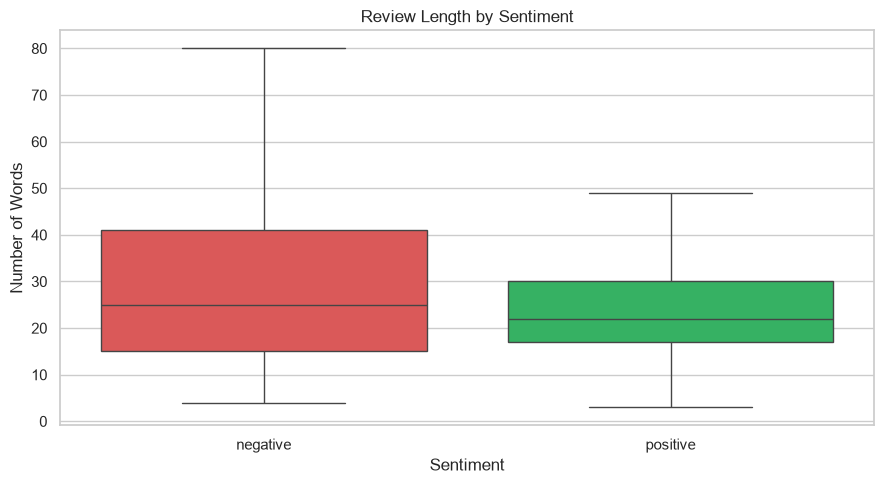

In [49]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="label",
    y="word_count",
    order=["negative", "positive"],
    hue="label",
    palette={
        "negative": "#EF4444",
        "positive": "#22C55E"
    },
    legend=False,
    showfliers=False
)

plt.title("Review Length by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Number of Words")
plt.tight_layout()
plt.show()

In [50]:
# Các trường hợp rating và label có vẻ không thống nhất
suspicious = df[
    ((df["rating"] <= 2) & (df["label"] == "positive")) |
    ((df["rating"] >= 4) & (df["label"] == "negative"))
]

print("Số review cần kiểm tra:", len(suspicious))

display(
    suspicious[
        ["rating", "label", "review"]
    ].sample(
        n=min(15, len(suspicious)),
        random_state=42
    )
)

Số review cần kiểm tra: 118


,rating,label,review
5603,5,negative,Shop giao lộn sz mình đặt 25-26 shop giao 27-28 bé nhà mình đi ko vừa
7845,4,negative,"Công dụng:sáng da? Mùi hương:thơm Phù hợp với loại da:da sốp mới móc ở đống rác lên rồi bỏ vào hộp gửi luôn à? bẩn thỉu nhọ nhem, nhận đc cái hộp nát bấy bên trong có 1 mảnh bọt khí với cái chai nhọ nhem, nhìn phát chán, mua sale của VHL cho uy tín mà shop giao hàng kiểu này thấy ko biết liệu có phải real hay ko hay hàng gì nữa"
479,4,negative,Chất lỏng le à tuoi tưởng đặc kẹo như hòi xưa Làm sạch ổn k khô da
4994,1,positive,Hương thơm:hang chuan
2564,4,negative,"Mùi hương:cool Công dụng:xúc miệng Gói hàng tệ không chịu được, khi nhận được hàng là hàng lủng ra luôn rồi"
9597,1,positive,Bao bì/Mẫu mã:mính đã nhận được hàng .đóng gói đẹp .giao hàng nhanh
6451,5,negative,Hình ảnh mang tính chất minh hoạ nhận xu..giao đúng hàng đúng sản phẩm nhưng hay bị móp méo do vận chuyển..đề nghị shop kêu vận chuyển nhẹ tay
1372,1,positive,"Sản phẩm đúng với mô tả trên trang web. Sản phẩm có chất lượng tốt, không bị hư hỏng. đúng với kích thước và màu sắc đã chọn."
7992,5,negative,"Nhận đc hàng nhưng bị móp từ hộp giấy bên ngoài đến hộp sữa bên trong, hơi buồn"
6518,5,negative,"Chất lượng sản phẩm:NHẠC KHÁ NHỎ Bật to hết cỡ mà nghe cũng bth kh thấy to, không khử tiếng ồn luôn vẫn nghe thấy âm thanh bên ngoài mặc dù đã mở to hết cỡ. Tai nghe vừa tai, cũng dễ chịu. Cái ốp kh vừa hay j nhìn thấy ghê thiệt chứ, thà k đeo còn hơn á"


In [51]:
import pandas as pd

pd.set_option("display.max_colwidth", None)

# Lọc các trường hợp rating và label không thống nhất
suspicious = df[
    ((df["rating"] <= 2) & (df["label"] == "positive")) |
    ((df["rating"] >= 4) & (df["label"] == "negative"))
].copy()

print("Tổng số review cần kiểm tra:", len(suspicious))

# Hiển thị 15 review ngẫu nhiên, không cắt nội dung
for idx, row in suspicious.sample(
    n=min(15, len(suspicious)),
    random_state=42
).iterrows():
    print("-" * 80)
    print(f"Index: {idx}")
    print(f"Rating: {row['rating']}")
    print(f"Label: {row['label']}")
    print(f"Review: {row['review']}")

Tổng số review cần kiểm tra: 118
--------------------------------------------------------------------------------
Index: 5603
Rating: 5
Label: negative
Review: Shop giao lộn sz mình đặt 25-26 shop giao 27-28 bé nhà mình đi ko vừa
--------------------------------------------------------------------------------
Index: 7845
Rating: 4
Label: negative
Review: Công dụng:sáng da? Mùi hương:thơm Phù hợp với loại da:da  sốp mới móc ở đống rác lên rồi bỏ vào hộp gửi luôn à? bẩn thỉu nhọ nhem, nhận đc cái hộp nát bấy bên trong có 1 mảnh bọt khí với cái chai nhọ nhem, nhìn phát chán, mua sale của VHL cho uy tín mà shop giao hàng kiểu này thấy ko biết liệu có phải real hay ko hay hàng gì nữa
--------------------------------------------------------------------------------
Index: 479
Rating: 4
Label: negative
Review: Chất lỏng le à tuoi tưởng đặc kẹo như hòi xưa Làm sạch ổn k khô da
--------------------------------------------------------------------------------
Index: 4994
Rating: 1
Label: positive


In [52]:
# Nhóm 1: Rating và Label có vẻ không thống nhất
group_1 = suspicious.sample(
    n=min(40, len(suspicious)),
    random_state=42
)

# Nhóm 2: Review 3 sao
group_2 = df[df["rating"] == 3].sample(
    n=40,
    random_state=42
)

# Nhóm 3: Mẫu ngẫu nhiên theo nhãn
group_3 = (
    df.groupby("label", group_keys=False)
      .sample(n=40, random_state=42)
)

# Gộp mẫu, loại ID trùng
audit = pd.concat([group_1, group_2, group_3])
audit = audit.drop_duplicates(subset="id")

# Cột để nhóm tự đánh giá
audit = audit[["id", "review", "rating", "label"]].copy()
audit["manual_label"] = ""
audit["notes"] = ""

# Xuất file CSV để kiểm tra
template_path = Path("../results/label_audit_template.csv")

if template_path.exists():
    print("File mẫu đã tồn tại, không ghi đè.")
else:
    audit.to_csv(
        template_path,
        index=False,
        encoding="utf-8-sig"
    )
    print("Đã tạo file mẫu:", template_path)

print("Số review cần kiểm tra:", len(audit))
display(audit.head())

File mẫu đã tồn tại, không ghi đè.
Số review cần kiểm tra: 159


,id,review,rating,label,manual_label,notes
5603,78893963805,Shop giao lộn sz mình đặt 25-26 shop giao 27-28 bé nhà mình đi ko vừa,5,negative,,
7845,88000990279,"Công dụng:sáng da? Mùi hương:thơm Phù hợp với loại da:da sốp mới móc ở đống rác lên rồi bỏ vào hộp gửi luôn à? bẩn thỉu nhọ nhem, nhận đc cái hộp nát bấy bên trong có 1 mảnh bọt khí với cái chai nhọ nhem, nhìn phát chán, mua sale của VHL cho uy tín mà shop giao hàng kiểu này thấy ko biết liệu có phải real hay ko hay hàng gì nữa",4,negative,,
479,62204355212,Chất lỏng le à tuoi tưởng đặc kẹo như hòi xưa Làm sạch ổn k khô da,4,negative,,
4994,54112684858,Hương thơm:hang chuan,1,positive,,
2564,14052566395,"Mùi hương:cool Công dụng:xúc miệng Gói hàng tệ không chịu được, khi nhận được hàng là hàng lủng ra luôn rồi",4,negative,,


In [53]:

import pandas as pd
from pathlib import Path

# 1. Đường dẫn file đã đánh giá thủ công
audit_path = Path("../results/label_audit_reviewed.csv")

# 2. Kiểm tra file tồn tại
if not audit_path.is_file():
    print("Chưa tìm thấy file label_audit_reviewed.csv.")
    print("Hãy kiểm tra thư mục results/ và đường dẫn file.")

else:
    # 3. Đọc file đã đánh giá 
    audit_reviewed = pd.read_csv(audit_path, encoding="utf-8-sig")

    # 4. Chuẩn hóa nhãn để tránh lỗi khoảng trắng hoặc chữ hoa
    audit_reviewed["label"] = (
        audit_reviewed["label"]
        .astype("string")
        .str.strip()
        .str.lower()
    )

    audit_reviewed["manual_label"] = (
        audit_reviewed["manual_label"]
        .astype("string")
        .str.strip()
        .str.lower()
    )

    # 5. Chỉ lấy các review đã được đánh giá thủ công
    valid_labels = ["positive", "negative", "neutral"]

    reviewed = audit_reviewed[
        audit_reviewed["manual_label"].isin(valid_labels)
    ].copy()

    print("Tổng số review trong file:", len(audit_reviewed))
    print("Số review đã kiểm tra:", len(reviewed))
    print("Số review chưa kiểm tra:", len(audit_reviewed) - len(reviewed))

    # 6. Thống kê phân bố nhãn thủ công
    print("\nPhân bố nhãn thủ công:")
    print(
        reviewed["manual_label"]
        .value_counts()
        .reindex(valid_labels, fill_value=0)
    )

    # 7. Bảng so sánh nhãn gốc và nhãn thủ công
    print("\nSo sánh nhãn gốc và nhãn thủ công:")

    comparison_table = pd.crosstab(
        reviewed["label"],
        reviewed["manual_label"]
    ).reindex(
        index=["negative", "positive"],
        columns=["negative", "neutral", "positive"],
        fill_value=0
    )

    display(comparison_table)

    # 8. Chỉ tính tỷ lệ khớp trên nhãn rõ ràng
    clear = reviewed[
        reviewed["manual_label"].isin(["positive", "negative"])
    ].copy()

    if len(clear) > 0:
        clear["is_match"] = (
            clear["label"] == clear["manual_label"]
        )

        matched = int(clear["is_match"].sum())
        mismatched = len(clear) - matched
        agreement = matched / len(clear) * 100

        print("\nKẾT QUẢ LABEL AUDIT")
        print(f"Số review có nhãn rõ ràng: {len(clear)}")
        print(f"Số review khớp nhãn: {matched}")
        print(f"Số review không khớp: {mismatched}")
        print(f"Tỷ lệ khớp: {agreement:.2f}%")

    else:
        print("\nChưa có review nào được gán Positive/Negative.")

    # 9. Thống kê Neutral riêng
    neutral_count = int(
        (reviewed["manual_label"] == "neutral").sum()
    )

    print(f"\nSố review được đánh giá Neutral: {neutral_count}")

    # 10. Hiển thị các trường hợp bất đồng nhãn
    if len(clear) > 0:
        disagreements = clear[
            ~clear["is_match"]
        ]

        print("\nCác review không khớp nhãn:")
        display(
            disagreements[
                ["id", "rating", "label", "manual_label", "review", "notes"]
            ]
        )


Tổng số review trong file: 159
Số review đã kiểm tra: 156
Số review chưa kiểm tra: 3

Phân bố nhãn thủ công:
manual_label
positive    53
negative    92
neutral     11
Name: count, dtype: Int64

So sánh nhãn gốc và nhãn thủ công:


manual_label,negative,neutral,positive
label,,,
negative,91,9,8
positive,1,2,45



KẾT QUẢ LABEL AUDIT
Số review có nhãn rõ ràng: 145
Số review khớp nhãn: 136
Số review không khớp: 9
Tỷ lệ khớp: 93.79%

Số review được đánh giá Neutral: 11

Các review không khớp nhãn:


,id,rating,label,manual_label,review,notes
2,62204355212,4,negative,positive,Chất lỏng le à tuoi tưởng đặc kẹo như hòi xưa Làm sạch ổn k khô da,Khách chỉ đang nghĩ là loại không như khách nghĩ nhưng vẫn tốt về chất lượng
23,78023671535,5,negative,positive,"Đợt này ăn nghe hơi mùi dầu thì phải, hạt thì vẫn giòn. Giao hàng nhanh lắm","Đánh giá tốt, khách cảm thấy khác so với lần đặt trước mà thôi"
36,86927419086,5,negative,positive,"đẹp, bao bì chắc chắn, lượng phấn nhiều, lúc nhận hàng phấn bị trào lên nắp hộp nhưng không ảnh hưởng nhiều đến sản phẩm, chỉ gây mất thẩm mỹ xíu. Ncl chất lượng rất ok","Đánh giá tốt, gói hàng chưa oke nhưng mà không ảnh hưởng sản phẩm"
37,79053564709,5,negative,positive,"Trc có sd srm nhà simple r nma ko hợp nay thấy ra mẫu mới nên cũng muốn trải nghiệm 😍😍.chai srm dính bụi , r mấy vệt đen nhỏ nha shop ơi 😭😭😭. shop có thể thay hình thức đóng goi đừng dán băng keo dễ dính bẩn lắm .","Khách có ý định thử sản phẩm, chỉ thấy đóng gói chưa tốt"
53,30474103224,3,negative,positive,Bao bì/Mẫu mã:bị móp mro Độ tuổi sử dụng:2 Chất lượng sản phẩm:tốt Hình ảnh mang tính chất săn xu. Sữa tốt cho bé mu nhiều lần rồi nên mua nhe mn,Đánh giá tốt
54,10688557650,3,negative,positive,Giao hàng nhanh. Đóng gói cẩn thận. Nhưng giải quyết vấn đề còn chưa giải quyết hết,Đánh giá tốt
68,11660452569,3,negative,positive,Chất lượng sản phẩm:được Bao bì/Mẫu mã:vận chuyển bị méo Độ tuổi sử dụng:1-3 tuổi Chuyên mua hàng của shop . Chất lượng thì tốt nhưng vận chuyển bị méo .,NaN
77,85549361929,3,negative,positive,"Chất lượng sản phẩm:Oki Đúng với mô tả:Đúng Nước bị chảy ra khi cho bình nằm ngang, khi để nước có ga để đứng cũng bị bay hơi và chảy ra nắp nha đc cái shop có tặng thêm quà",NaN
148,55311498730,5,positive,negative,Khô vlinnnn thề đấy mn đừng mua khô hơn cả headandshoulder ý khô dã man sấy xong cứ bết bết,NaN


In [55]:

from collections import Counter
import re
import pandas as pd

def get_top_words(texts, top_n=20):
    counter = Counter()

    for text in texts:
        text = str(text).lower()

        # Tách token thô, hỗ trợ ký tự Unicode tiếng Việt
        words = re.findall(r"\b\w+\b", text, flags=re.UNICODE)

        counter.update(words)

    return pd.DataFrame(
        counter.most_common(top_n),
        columns=["word", "frequency"]
    )

# Từ phổ biến trong Positive
positive_words = get_top_words(
    df.loc[df["label"] == "positive", "review"]
)

# Từ phổ biến trong Negative
negative_words = get_top_words(
    df.loc[df["label"] == "negative", "review"]
)

print("TOP 20 TỪ PHỔ BIẾN - POSITIVE")
display(positive_words)

print("\nTOP 20 TỪ PHỔ BIẾN - NEGATIVE")
display(negative_words)


TOP 20 TỪ PHỔ BIẾN - POSITIVE


,word,frequency
0,hàng,1947
1,nhanh,1515
2,giao,1445
3,mua,1410
4,chất,1352
5,sản,1177
6,phẩm,1175
7,thơm,1158
8,dụng,1144
9,da,1124



TOP 20 TỪ PHỔ BIẾN - NEGATIVE


,word,frequency
0,hàng,4546
1,có,3209
2,không,2827
3,mua,2592
4,shop,2462
5,thì,2412
6,mà,2335
7,ko,2306
8,mình,2094
9,bị,2021


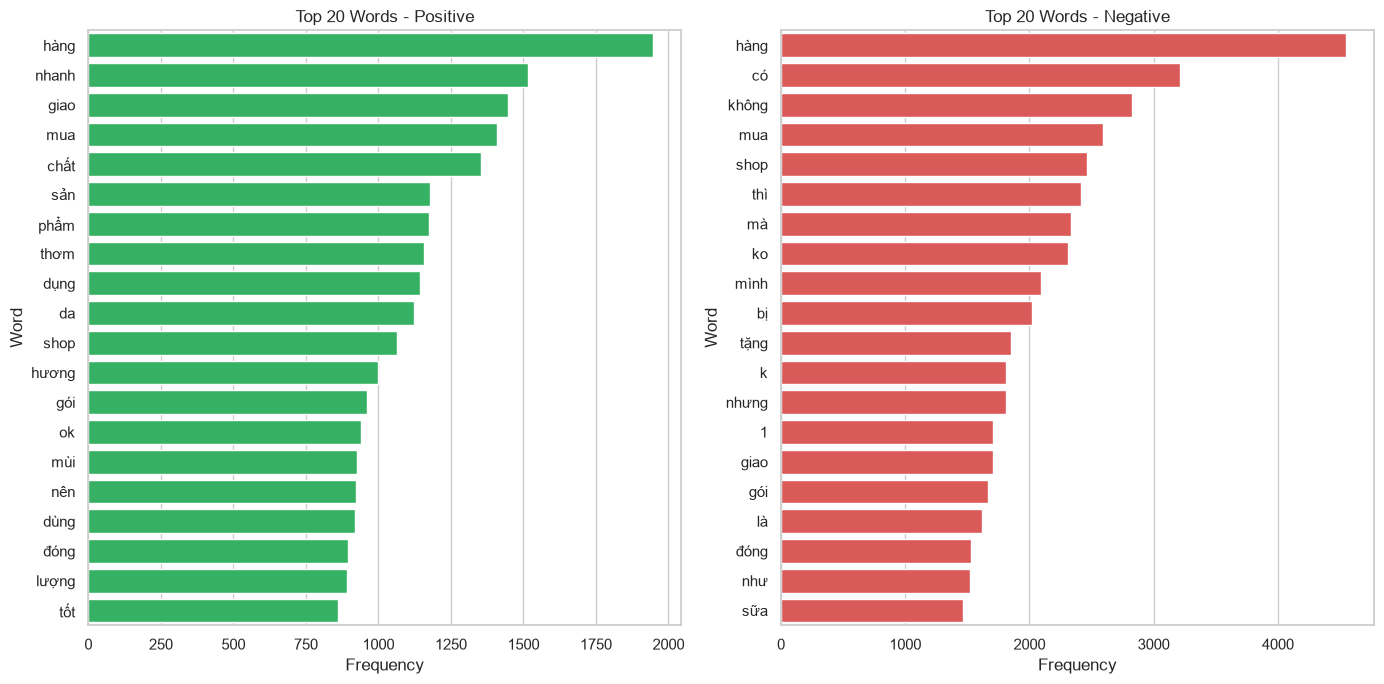

In [56]:

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

# Positive
sns.barplot(
    data=positive_words,
    x="frequency",
    y="word",
    color="#22C55E",
    ax=axes[0]
)

axes[0].set_title("Top 20 Words - Positive")
axes[0].set_xlabel("Frequency")
axes[0].set_ylabel("Word")

# Negative
sns.barplot(
    data=negative_words,
    x="frequency",
    y="word",
    color="#EF4444",
    ax=axes[1]
)

axes[1].set_title("Top 20 Words - Negative")
axes[1].set_xlabel("Frequency")
axes[1].set_ylabel("Word")

plt.tight_layout()
plt.show()


In [57]:

from collections import Counter
import re
import pandas as pd

def get_top_bigrams(texts, top_n=20):
    counter = Counter()

    for text in texts:
        words = re.findall(
            r"\b\w+\b",
            str(text).lower(),
            flags=re.UNICODE
        )

        bigrams = [
            f"{words[i]} {words[i + 1]}"
            for i in range(len(words) - 1)
        ]

        counter.update(bigrams)

    return pd.DataFrame(
        counter.most_common(top_n),
        columns=["bigram", "frequency"]
    )

positive_bigrams = get_top_bigrams(
    df.loc[df["label"] == "positive", "review"]
)

negative_bigrams = get_top_bigrams(
    df.loc[df["label"] == "negative", "review"]
)

print("TOP 20 BIGRAM - POSITIVE")
display(positive_bigrams)

print("\nTOP 20 BIGRAM - NEGATIVE")
display(negative_bigrams)


TOP 20 BIGRAM - POSITIVE


,bigram,frequency
0,sản phẩm,1155
1,giao hàng,1110
2,hàng nhanh,975
3,đóng gói,850
4,chất lượng,814
5,sử dụng,711
6,cẩn thận,569
7,bao bì,520
8,hương thơm,476
9,mùi hương,437



TOP 20 BIGRAM - NEGATIVE


,bigram,frequency
0,đóng gói,1194
1,sản phẩm,1106
2,bao bì,775
3,chất lượng,666
4,quà tặng,658
5,giao hàng,612
6,sử dụng,598
7,không có,468
8,có quà,425
9,thất vọng,407


In [58]:

import pandas as pd

reviews = df["review"].fillna("").astype(str)

patterns = {
    "URL": r"https?://\S+|www\.\S+",
    "HTML tags": r"<[^>]+>",
    "Email": r"\b[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}\b",
    "Phone-like numbers": r"(?<!\d)(?:\+84|0)\d{9,10}(?!\d)",
    "Multiple spaces": r" {2,}",
    "Repeated punctuation": r"[!?.,]{3,}",
    "Abbreviation 'ko'": r"(?i)\bko\b",
    "Abbreviation 'k'": r"(?i)\bk\b",
    "Abbreviation 'khum'": r"(?i)\bkhum\b",
}

results = []

for name, pattern in patterns.items():
    count = reviews.str.contains(
        pattern,
        regex=True,
        na=False
    ).sum()

    results.append({
        "issue": name,
        "review_count": int(count),
        "percentage": round(count / len(df) * 100, 2)
    })

noise_summary = pd.DataFrame(results)

display(noise_summary)


,issue,review_count,percentage
0,URL,1,0.01
1,HTML tags,0,0.00
2,Email,0,0.00
3,Phone-like numbers,6,0.06
4,Multiple spaces,3335,34.74
5,Repeated punctuation,258,2.69
6,Abbreviation 'ko',1621,16.89
7,Abbreviation 'k',1383,14.41
8,Abbreviation 'khum',3,0.03


In [59]:

# Lấy ví dụ có cách viết tắt "ko" hoặc "k"
mask = reviews.str.contains(
    r"(?i)\b(ko|k)\b",
    regex=True,
    na=False
)

examples = df.loc[
    mask,
    ["review", "label"]
].sample(
    n=min(10, mask.sum()),
    random_state=42
)

pd.set_option("display.max_colwidth", None)
display(examples)


C:\Users\nguye\AppData\Local\Temp\ipykernel_11268\1545307585.py:2: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  mask = reviews.str.contains(


,review,label
5291,Chất liệu:ok Màu sắc:ok Đúng với mô tả:ok M đã mua l2 nên k cần phải đánh giá,positive
7339,Bao bì:1thùng bị thiếu 1 vỉ . thùng tự dính lại băng dính ko nguyên vẹn,negative
7773,"Mua về tg đc quà tặng ai ngờ là mỗi cái dầu gội ko có tặng kèm ,mọi người chú ý nha ,shop để nguyên hình có quà tặng nhưng mà chữ mua kèm deal sốc thì bé, những hãng khác ghi quà tặng là tặng luôn ,hãng này còn phải mua kèm ,1 số ng ko bt là mất luôn,săn live nên thấy ms mua vậy ,chán quá mn chú ý .Gói hàng cũng hơi sơ sài ,co 1 miếng sốc duy nhất.",negative
7225,Nghe quảng cáo mua dùng và thật sự thấy ko như lời đồn,negative
7577,Ko có quà tặng kèm như hình,negative
8465,"Giao hàng nhanh, đóng gói cẩn thận, miếng dán lệch so với khung nên dán kiếng ko dc ở giữa điẹn thoại",negative
8114,quà tặng phải đọc kĩ tìm hiểu cho rõ chứ lơ tơ mơ là bị hiểu sai liềnm nt hỏi shop tl rất dài dòng đa số tn tự động k làm rõ vẫn đề. tóm lại mua đúg ngày kmai luôn nhưng k nhập mã code k dc tặng,negative
6414,"Ko biết là do đâu mà hàng nhập về tay hộp móp hết Đóng gói sơ sài, hãng gì mà keo, cái tấm chống xốc có tí tẹo, hàng bung ra hết",negative
1403,Cần shop giải thích . Vì sao sữa bị bục vẫn đóng gửi cho khách . Trong khi 1kiện gửi cùng đóng gói sơ sài thì ko bị bục . Đây đóng gói rất kỹ càng lại bị bục ra đổ hết sữa ra ngoài .,negative
7246,"Chất lượng sản phẩm:ok Bao bì/Mẫu mã:bị méo hộp Độ tuổi sử dụng:2-6 Giao hàng nhanh, giao thiếu quà nhắn tin shop ko rep tin nhắn , ko có quà thì báo cũng ko nói, dịch vụ chăm sóc khách hàng chỉ đc 0 sao. Nói chung ko hài lòng về dịch vụ của shop.",negative


In [61]:

import re
import unicodedata
import pandas as pd

# Quy tắc chuẩn hóa một số từ phủ định viết tắt
NEGATION_MAP = {
    "ko": "không",
    "k": "không",
    "khum": "không",
}

NEGATION_PATTERN = re.compile(
    r"\b(?:ko|k|khum)\b",
    flags=re.IGNORECASE
)

URL_PATTERN = re.compile(
    r"https?://\S+|www\.\S+",
    flags=re.IGNORECASE
)

WHITESPACE_PATTERN = re.compile(r"\s+")

def preprocess_text(text):
    if pd.isna(text):
        return ""

    # 1. Chuyển thành chuỗi
    text = str(text)

    # 2. Chuẩn hóa Unicode tiếng Việt
    text = unicodedata.normalize("NFC", text)

    # 3. Chuyển chữ thường
    text = text.lower()

    # 4. Xóa URL
    text = URL_PATTERN.sub(" ", text)

    # 5. Chuẩn hóa từ phủ định viết tắt
    text = NEGATION_PATTERN.sub(
        lambda match: NEGATION_MAP[match.group(0)],
        text
    )

    # 6. Chuẩn hóa khoảng trắng
    text = WHITESPACE_PATTERN.sub(" ", text).strip()

    return text


In [62]:

# Tạo cột văn bản đã chuẩn hóa để khảo sát
df["review_clean"] = df["review"].apply(preprocess_text)

# So sánh mẫu ngẫu nhiên
sample = df[
    ["review", "review_clean", "label"]
].sample(
    n=10,
    random_state=42
)

pd.set_option("display.max_colwidth", None)

display(sample)

# Thống kê số review thay đổi
changed = (
    df["review"] != df["review_clean"]
).sum()

print("Tổng số review:", len(df))
print("Số review có thay đổi:", changed)
print(f"Tỷ lệ thay đổi: {changed / len(df) * 100:.2f}%")

# Kiểm tra review rỗng sau xử lý
empty_after = (
    df["review_clean"]
    .str.strip()
    .eq("")
    .sum()
)

print("Review rỗng sau xử lý:", empty_after)


,review,review_clean,label
1318,Giá rẻ thì ko có hàng bổ đâu nha mn. Lộ rãnh môi nhiều và son màu ko tươi như ảnh.,giá rẻ thì không có hàng bổ đâu nha mn. lộ rãnh môi nhiều và son màu không tươi như ảnh.,negative
9503,Chưa dùng nhưng hộp rất đẹp và xịn Đừng chờ đợi những gì bạn ước muốn mà hãy đi tìm kiếm chúng. Tôi không bao giờ hối hận với những gì mình đã làm. Tôi chỉ hối hận với những việc mình đã không làm khi có cơ hội.,chưa dùng nhưng hộp rất đẹp và xịn đừng chờ đợi những gì bạn ước muốn mà hãy đi tìm kiếm chúng. tôi không bao giờ hối hận với những gì mình đã làm. tôi chỉ hối hận với những việc mình đã không làm khi có cơ hội.,positive
7222,Mùi hương:thom Dành cho tóc:khô xơ Công dụng:tạp nếp và dưỡng tóc Shop đóng hàng khá cẩn thận sản phẩm được bọc vào túi chống shock bằng chai thủy tinh trong khá lịch sự và sang trọng mùi thơm nhưng mình thấy thành phẩm này phù hợp cho việc tạo nếp tóc hơn là dưỡng tóc,mùi hương:thom dành cho tóc:khô xơ công dụng:tạp nếp và dưỡng tóc shop đóng hàng khá cẩn thận sản phẩm được bọc vào túi chống shock bằng chai thủy tinh trong khá lịch sự và sang trọng mùi thơm nhưng mình thấy thành phẩm này phù hợp cho việc tạo nếp tóc hơn là dưỡng tóc,positive
5391,"siêu lành tính, dịu nhẹ cho mọi làn da, dưỡng ẩm tốt cho cả người lớn lẫn trẻ con lun, ước gì shop có size to hơn ạ","siêu lành tính, dịu nhẹ cho mọi làn da, dưỡng ẩm tốt cho cả người lớn lẫn trẻ con lun, ước gì shop có size to hơn ạ",positive
9165,Mình da dầu nhưng dùng bản này thấy vẫn bi khô da lắm í vừa bôi xong thấy mốc rồi nâng tông vừa phải,mình da dầu nhưng dùng bản này thấy vẫn bi khô da lắm í vừa bôi xong thấy mốc rồi nâng tông vừa phải,negative
8940,Hãng giao hàng gói rất sơ sài! Không hề có chống shock. Chỉ gói 2 thùng lại với nhau bằng màng co bình thường. Một số bịch trong thùng bị bể. Sau vài ngày mình mới phát hiện ra do có mùi chua. Nói chung mình sẽ ko mua sữa của hãng trên shopee nữa! Rất thất vọng về cách xử lý huỷ đơn và cách gói hàng của shop,hãng giao hàng gói rất sơ sài! không hề có chống shock. chỉ gói 2 thùng lại với nhau bằng màng co bình thường. một số bịch trong thùng bị bể. sau vài ngày mình mới phát hiện ra do có mùi chua. nói chung mình sẽ không mua sữa của hãng trên shopee nữa! rất thất vọng về cách xử lý huỷ đơn và cách gói hàng của shop,negative
3708,Làm đẹp:ok Mẹo:ok Bao bì:tot Đầy đủ số lượng và màu sắc đúng mẫu luôn tất siêu yêu cưng lắm ý sét màu hồng và nâu yêu cực nha,làm đẹp:ok mẹo:ok bao bì:tot đầy đủ số lượng và màu sắc đúng mẫu luôn tất siêu yêu cưng lắm ý sét màu hồng và nâu yêu cực nha,positive
3573,"Công dụng:nhuộm tóc Mùi hương:thơm lắm Giao nhanh lắm, mới đặt hôm qua hôm nay giao rồi, mùi rất thơm, sẽ ủng hộ shop lần sau","công dụng:nhuộm tóc mùi hương:thơm lắm giao nhanh lắm, mới đặt hôm qua hôm nay giao rồi, mùi rất thơm, sẽ ủng hộ shop lần sau",positive
683,Hương vị:mua chưa thanh toán thi đơn giao rất nhanh và thùng giao tới không bị móp méo. mua thanh toán ngay thì thời gian nhà bán giao cho đơn vị vận chuyển rất lâu. đóng 2 thùng đè lên nhau. thùng dưới bị móp biến dạng và ướt. mở thùng đổ bịch sữa ra ngoài thì thấy mùi rất thối. một cảm giác rất tồi tệ khi nhận phải dịch vụ kém chất lượng và chất lượng hàng hóa cũng kém (bịch sữa ám mùi thối),hương vị:mua chưa thanh toán thi đơn giao rất nhanh và thùng giao tới không bị móp méo. mua thanh toán ngay thì thời gian nhà bán giao cho đơn vị vận chuyển rất lâu. đóng 2 thùng đè lên nhau. thùng dưới bị móp biến dạng và ướt. mở thùng đổ bịch sữa ra ngoài thì thấy mùi rất thối. một cảm giác rất tồi tệ khi nhận phải dịch vụ kém chất lượng và chất lượng hàng hóa cũng kém (bịch sữa ám mùi thối),negative
9036,Mua 2 cây đc tặng túi đựng son mini. T mua 3 màu rồi. Chất mướt okela,mua 2 cây đc tặng túi đựng son mini. t mua 3 màu rồi. chất mướt okela,positive


Tổng số review: 9599
Số review có thay đổi: 9176
Tỷ lệ thay đổi: 95.59%
Review rỗng sau xử lý: 0


In [63]:

examples = [
    "Shop giao hàng ko đúng mẫu",
    "Sản phẩm k tốt như quảng cáo",
    "Mình khum thích mùi này",
    "Chất lượng tốt, giao hàng nhanh",
    "Không hài lòng vì hàng bị lỗi"
]

for text in examples:
    print("Gốc:     ", text)
    print("Sau xử lý:", preprocess_text(text))
    print("-" * 60)


Gốc:      Shop giao hàng ko đúng mẫu
Sau xử lý: shop giao hàng không đúng mẫu
------------------------------------------------------------
Gốc:      Sản phẩm k tốt như quảng cáo
Sau xử lý: sản phẩm không tốt như quảng cáo
------------------------------------------------------------
Gốc:      Mình khum thích mùi này
Sau xử lý: mình không thích mùi này
------------------------------------------------------------
Gốc:      Chất lượng tốt, giao hàng nhanh
Sau xử lý: chất lượng tốt, giao hàng nhanh
------------------------------------------------------------
Gốc:      Không hài lòng vì hàng bị lỗi
Sau xử lý: không hài lòng vì hàng bị lỗi
------------------------------------------------------------
